# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** (https://nuaq2005.streamlit.app/)

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [1]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [4]:
# Your data checks here
print("Shape: ", df.shape)

print("Missing values: ", df.isna().sum().sum())
print("Duplicated rows: ", df.duplicated().sum())

print("Data types: ", df.info())
#zipcode could be int, so could year and decade


Shape:  (100000, 13)
Missing values:  60
Duplicated rows:  0
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   user_id      100000 non-null  int64  
 1   movie_id     100000 non-null  int64  
 2   rating       100000 non-null  int64  
 3   timestamp    100000 non-null  str    
 4   age          100000 non-null  int64  
 5   gender       100000 non-null  str    
 6   occupation   100000 non-null  str    
 7   zip_code     100000 non-null  str    
 8   title        100000 non-null  str    
 9   year         99970 non-null   float64
 10  decade       99970 non-null   float64
 11  genres       100000 non-null  str    
 12  rating_year  100000 non-null  int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 16.6 MB
Data types:  None


In [5]:
print("Value counts: ", df["occupation"].value_counts(dropna=False)) 
#change none to n/a?


Value counts:  occupation
student          21957
other            10663
educator          9442
engineer          8175
programmer        7801
administrator     7479
writer            5536
librarian         5273
technician        3506
executive         3403
healthcare        2804
artist            2308
entertainment     2095
scientist         2058
marketing         1950
retired           1609
lawyer            1345
none               901
salesman           856
doctor             540
homemaker          299
Name: count, dtype: int64


In [6]:
print("Value counts: ", df["genres"].value_counts(dropna=False))
#maybe add a column splitting the genres into separate values

Value counts:  genres
Drama                        13257
Comedy                        9828
Comedy|Romance                5055
Drama|Romance                 4767
Action|Thriller               3550
                             ...  
Action|Adventure|Children        5
Action|Comedy|Crime|Drama        5
Crime|Film-Noir                  4
Fantasy                          1
Comedy|Documentary               1
Name: count, Length: 216, dtype: int64


In [7]:
print("Summary statistics: \n", df[['rating', 'age', 'year', 'decade', 'rating_year']].describe().round(2))
#why are there 30 entries missing from year and decade?

Summary statistics: 
           rating        age      year    decade  rating_year
count  100000.00  100000.00  99970.00  99970.00    100000.00
mean        3.53      32.97   1987.75   1982.78      1997.47
std         1.13      11.56     14.14     13.82         0.50
min         1.00       7.00   1922.00   1920.00      1997.00
25%         3.00      24.00   1986.00   1980.00      1997.00
50%         4.00      30.00   1994.00   1990.00      1997.00
75%         4.00      40.00   1996.00   1990.00      1998.00
max         5.00      73.00   1998.00   1990.00      1998.00


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_
- There were no duplicates and only a few nas. The zipcodes are strings instead of integers, and genres has so many different combos you can't properly group by genre. Also for some reason there is thirty missing values for year and decade. 

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: I will count ratings. I will handle it by counting the rating towards each genre.
- Why: Movies are individually titled and won't really reflect a story with genres. With ratings, we can find out how each genre is liked by the audience. The number of movies by genre can reflect demand, but it could reflect what directors think the audience wants. 

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: Average rating by each genre. I will treat it by running multiple simulations.  
- Why: It will give a clear picture as to how satisfied by these genres the audience is. The multiple simulations will give a more balanced result for genres  with smaller number of ratings. 

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: No. I will drop it. 
- Why: There are about thirty movies that have no year, which isn't much in the face of 10,000 entries, but too many for me to individually check. 

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: A movies rating is the mean of the user's ratings measured on a scale of 1-5, with at least 50 ratings which is ≥. If there is a tie, Then we will look at median as well. 
- Why: The mean provides an average for every movie, and having the sample size be at least 50 allows us to not have movies severly overrated or underrated because of a few skewed ratings. 

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

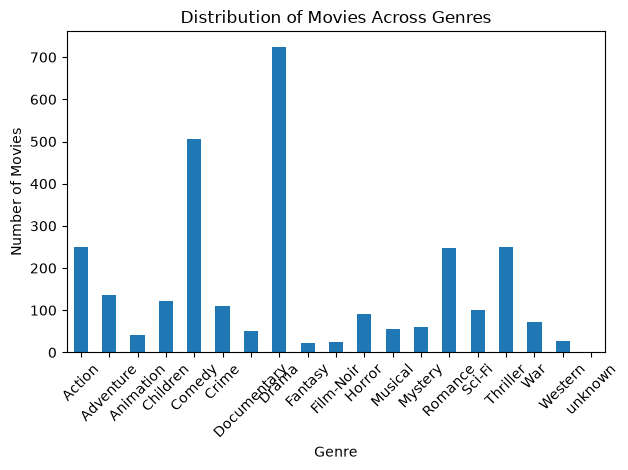

In [65]:
# Q1: your code here
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
ratings = genre_df.groupby('genre')['rating']

#chart it
genre_df.groupby('genre')['movie_id'].nunique().plot(kind='bar')

plt.xlabel('Genre')
plt.ylabel('Number of Movies')
plt.title('Distribution of Movies Across Genres')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_
Drama, Comedy and Action are dominating by a large amount. There are over 700 ratings for drama, about 500 for Comedy and a little above 200 for Thriller. All the other genres have much less. I counted number of ratings by genre. 

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

In [73]:
# Q2: your code here
genre_stats = genre_df.groupby('genre').agg( average_rating=('rating', 'mean'), count=('movie_id', 'nunique')).round(2)

genre_stats = genre_stats.sort_values( 'average_rating', ascending=False)

genre_stats


,average_rating,count
genre,,
Film-Noir,3.92,24
War,3.82,71
Drama,3.69,725
Documentary,3.67,50
Mystery,3.64,61
Crime,3.63,109
Romance,3.62,247
Western,3.61,27
Animation,3.58,42


**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_
Top genre is Film Noir at 3.92, while the bottom is unknown at 3.20.  Film Noir took its data from 24 ratings while unknown took it from 2, very small data pools. 

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

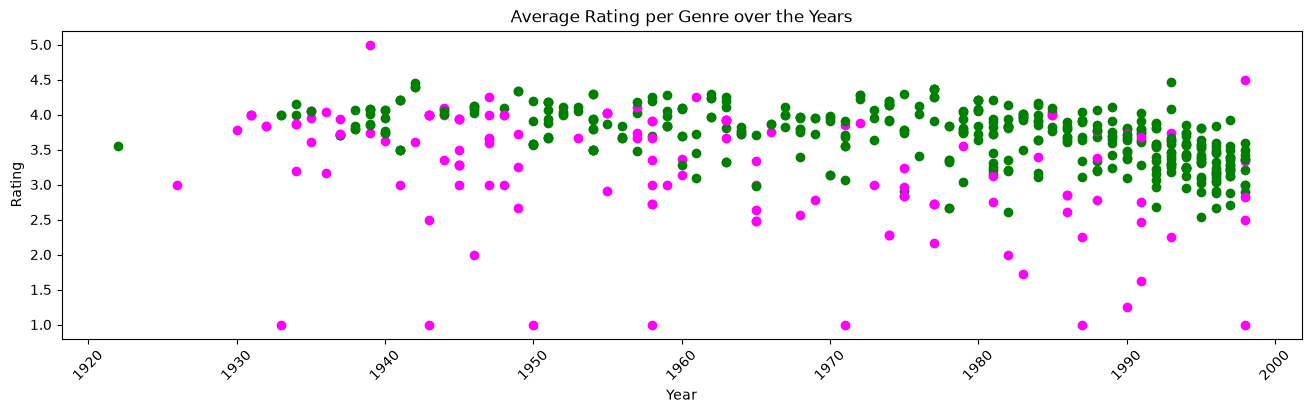

,Genre,Year,Average Rating,Number of Ratings
0,Action,1938.0,3.79,67
1,Action,1951.0,4.18,152
2,Action,1954.0,3.94,121
3,Action,1959.0,3.83,124
4,Action,1965.0,3.00,7
...,...,...,...,...
533,Western,1993.0,3.62,117
534,Western,1994.0,3.24,319
535,Western,1995.0,3.34,94
536,Western,1996.0,2.66,53


In [ ]:
# Q3: your code here

#dot graph for each genre's average rating over the years because the line graph looked crazy
plt.figure(figsize=(16, 4))

for genre, group in genre_df.groupby('genre'):
    average = group.groupby('year')['rating'].mean().sort_index()
    red = group.groupby('year')['rating'].count() <= 50
    green = group.groupby('year')['rating'].count() > 50
    
    plt.scatter(average.index[red], average.values[red], label=genre, color='magenta')
    plt.scatter(average.index[green], average.values[green], label=genre, color='green')

plt.xticks(rotation=45)
plt.xlabel('Year')
plt.ylabel('Rating')
plt.title('Average Rating per Genre over the Years')
plt.show()

#table for values
genre_stats = (
    genre_df.groupby(['genre', 'year'])['rating']
    .agg(['mean', 'count'])
    .reset_index()
)

genre_stats.columns = ['Genre', 'Year', 'Average Rating', 'Number of Ratings']
genre_stats['Average Rating'] = genre_stats['Average Rating'].round(2)

genre_stats

**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_
The genres with more than 50 ratings(green dots) to calculate the average from are clustered within a tighter range of 4.5 - 3.0. The genres with less than 50 ratings (pink dots) are much more sporadic, with extreme highs and lows. I would say the genres with less than 50 reviews are less believable than those with more than 50.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [63]:
# Q4: your code here

#find five best rated movies with at least 50 ratings
# print(f"Best Five with Floor of 50 Ratings: \n")
# best_rated_movies = genre_df.groupby('title')['rating'].agg(['mean', 'count']).reset_index()
# best_rated_movies = best_rated_movies[best_rated_movies['count'] >= 50]
# best_rated_movies = best_rated_movies.sort_values('mean', ascending=False).head(5)
# best_rated_movies

print(f"Best Five with Floor of 150 Ratings: \n")
best_hundred = genre_df.groupby('title')['rating'].agg(['mean', 'count']).reset_index()
best_hundred = best_hundred[best_hundred['count'] >= 150]
best_hundred = best_hundred.sort_values('mean', ascending=False).head(5)
best_hundred
    

Best Five with Floor of 150 Ratings: 



,title,mean,count
318,"Close Shave, A (1995)",4.491071,336
1281,Schindler's List (1993),4.466443,596
1652,"Wrong Trousers, The (1993)",4.466102,236
273,Casablanca (1942),4.456790,729
1317,"Shawshank Redemption, The (1994)",4.445230,283


**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_
Just the fifth place was swapped out. At a floor of fifty movies, _Wallace & Grommit: The Best of Aardman Animation_ was in fifth place with 67 ratings. At a floor of a hundred and fifty movies, it is _Shawshank Redemption, The.._ with 283 ratings. This tells me that often times a smaller amount pool of data will give a less reliable view of the movies overall rating as any low or high rating can skew the result.

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked: In short, I said, "With the following fields in csv file, give the code for charts answering the following questions"
- AI's first attempt: It was largely correct
- What I changed (or accepted without checking): I changed a few lines for formatting to make bars more distinct, or hover over to read charts

**Prompt 2**
- What I asked: I asked "I would like to divide the genres by the pipe seperation into individual genres rather than reading the pipe seperated genres as one string"
- AI's first attempt: It gave me a few lines that remedied this problem
- What I changed (or accepted without checking): I accepted without checking

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: Drama, Comedy, Thriller
- I say: Drama, Comedy, Thriller
- Same? (yes / partly / no): yes
- If different, why?

**Q2**
- Dashboard says: Film Noir, Unknown
- I say: Film Noir, Unknown
- Same? (yes / partly / no): yes
- If different, why?

**Q3**
- Dashboard says: A line running over the years 1922 to 1998 showing average rating by year
- I say: A scatter plot showing each genres average rating by year
- Same? (yes / partly / no):No
- If different, why? It is definitely because I misunderstood the question, I thought it wanted average by year in relation to genre

**Q4**
- Dashboard says: 
    - Top five with floor of fifty is Close Shave, Schindler's List, Wrong Trousers, The, Casablanca, and Wallace & Gromit. 
    - Top five with floor of one fifty is Schindler's List, Casablanca, Shawshank Rdemption, The, Rear Window, and Usual Suspects, The.
- I say:
    - Top five with floor of fifty is Close Shave, Schindler's List, Wrong Trousers, The, Casablanca, and Wallace & Gromit.
    - Top five with floor of one hundred and fifty is Close Shave, Schindler's List, Wrong Trousers, The, Casablanca, and Shawshank Redemption, The
- Same? (yes / partly / no): partly
- If different, why? I think it counted rows for my one rather than counting movies.

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used: Bar
- Chart I used: Bar
- Which communicates the answer better, and why? Bar is best to visualize the differing count and average by genre.

**Q2**
- Chart the dashboard used: Bar
- Chart I used: Table
- Which communicates the answer better, and why? I think table actually, because on bar graph the difference is so small on scale that seeing the numerical difference helps to see the picture better. 

**Q3**
- Chart the dashboard used: Dotted Line
- Chart I used: Scatter Plot
- Which communicates the answer better, and why? We kind of answered two different questions, but for mean by year, the dotted line is much better. The line represents the transition in change by year, and the dots give a concrete value. 

**Q4**
- Chart the dashboard used: Bar
- Chart I used: Table
- Which communicates the answer better, and why? Table again, because once again the ratings are so similar that seeing the numerical rating helps to diffrentiate better. 

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

Some of the charts are sorted by rating, and some by count. The labels are readable and the axes are honest for both, but I will say for chart choice my version is actually better in some aspects as it shows the data behind each number more clearly. However, the AI did style the charts in a more interactable and clear manner.

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*


**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*



**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

1. The users gave between 20 - 737 ratings with an average of about 106 ratings per user. They also all did ratings between the years 1997-1998. This suggests al lot of  information was collected within a two year range, so it can be biased by what genre was favored in those years. My Q2 answer on average ratings may not be accurate to the entire populations' preferences. 

2. Let's look at Fantasy (because unknown isn't really a genre). It has an average of 3.22 and only 22 movies to take data from. The 95% interval is 2.51 to 3.19, meaning the actual average is in between. 

3. It appears ALL of the ratings occur between the years 1997 and 1998. The audience would primarily enjoy movies in that time frame or slightly before out of nostalgia, and not like anything too new or old. So it's not really ratings by year, more so how people in 1997-1998 rate movies of each year. 

In [ ]:
user_counts = df.groupby('user_id').size()
print("Fewest ratings:", user_counts.min())
print("Most ratings:", user_counts.max())
print("Average ratings per user:", user_counts.mean())



Fewest ratings: 20
Most ratings: 737
Average ratings per user: 106.04453870625663


In [80]:
print(df['rating_year'].describe())
print(df['rating_year'].value_counts().sort_index())

count    100000.000000
mean       1997.471010
std           0.499161
min        1997.000000
25%        1997.000000
50%        1997.000000
75%        1998.000000
max        1998.000000
Name: rating_year, dtype: float64
rating_year
1997    52899
1998    47101
Name: count, dtype: int64


In [ ]:
#2

# Get Fantasy ratings from the original dataframe
fantasy = genre_df[genre_df['genre'] == 'Fantasy']

# Count ratings and distinct movies
n_ratings = fantasy['rating'].count()
n_movies = fantasy['movie_id'].nunique()

mean_rating = fantasy['rating'].mean()
std_rating = fantasy['rating'].std()


# Better check: treat each movie as one observation
movie_means = fantasy.groupby('movie_id')['rating'].mean()

movie_mean = movie_means.mean()
movie_std = movie_means.std()
movie_n = len(movie_means)

movie_margin = 1.96 * movie_std / (movie_n ** 0.5)

print("Movie-level average:", round(movie_mean, 2))
print("Movie-level 95% interval:",
      round(movie_mean - movie_margin, 2),
      "to",
      round(movie_mean + movie_margin, 2))


Movie-level average: 2.85
Movie-level 95% interval: 2.51 to 3.19


In [85]:
print(df.rating_year.describe())

count    100000.000000
mean       1997.471010
std           0.499161
min        1997.000000
25%        1997.000000
50%        1997.000000
75%        1998.000000
max        1998.000000
Name: rating_year, dtype: float64


## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better): What kind of chart works best.

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):
Formatting, counting by unique movies and not rows. 

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?
Last week it was definitely the AI doing the legwork, but this time I had to think pretty hard about the data and understand it before choosing my charts and how to make them. Last time I revised what the AI did, while this time I later compared and asked AI what went wrong with my work. 

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week